# 02 — Memahami dataset buku

Sebelum membersihkan data, saya perlu mengetahui karakteristik katalog: apakah semua buku punya abstrak, bahasa apa yang dominan, tahun berapa saja yang tercakup, dan bagaimana distribusi kategori. Tujuannya supaya keputusan preprocessing tidak dibuat berdasarkan perkiraan.

## 1. Membaca file sumber

In [1]:
from pathlib import Path
import re, html, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / 'data' / 'dataset_buku_2000.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'dataset_buku_2000.csv').exists(), 'Buka folder utama proyek atau notebook dari subfolder notebooks.'
DATA = ROOT / 'data'
OUT = ROOT / 'outputs'
FIG = ROOT / 'figures'
OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)
books = pd.read_csv(DATA / 'dataset_buku_2000.csv', dtype=str).fillna('')
comps = pd.read_csv(DATA / 'competencies_green.csv', dtype=str).fillna('')
print(f'Buku: {len(books):,} | Kompetensi: {len(comps)}')

Buku: 973 | Kompetensi: 67


## 2. Struktur dan tipe kolom
Jumlah baris pada nama file tidak selalu sama dengan isi aktual.

In [2]:
struktur = pd.DataFrame({'kolom': books.columns,
    'tipe': [str(books[k].dtype) for k in books.columns],
    'terisi': [(books[k].str.strip() != '').sum() for k in books.columns],
    'nilai_unik': [books[k].nunique() for k in books.columns]})
display(struktur)
print('Ukuran:', books.shape)

,kolom,tipe,terisi,nilai_unik
0,book_id,str,973,973
1,judul,str,973,937
2,tahun,str,973,53
3,abstrak,str,973,968
4,kategori_buku,str,973,57
5,kompetensi,str,973,926
6,author,str,973,942
7,isbn,str,677,678
8,bahasa,str,973,4
9,sumber,str,973,1


Ukuran: (973, 13)


## 3. Contoh isi metadata
Saya hanya menampilkan beberapa baris agar notebook tetap mudah dibaca.

In [3]:
display(books[['book_id','judul','tahun','abstrak','kategori_buku','author','bahasa']].head(5).T)
print('Jumlah judul unik:', books.judul.nunique())

,0,1,2,3,4
book_id,BK00001,BK00002,BK00003,BK00004,BK00005
judul,Business Growth Strategy,Mastering Business Growth Strategies,AI-Powered Business Growth Strategies,Wise Growth Strategies in Leading Family Busin...,Analysis of growth strategies. Organic vs. ino...
tahun,2026,2020,2026,2005,2017
abstrak,"Introduction I wrote this book, “Business Grow...",Mastering Business Growth Strategies: Gaining ...,AI-Powered Business Growth Strategies is a pra...,The majority of family businesses are both ill...,Seminar paper from the year 2016 in the subjec...
kategori_buku,Antiques & Collectibles,Art,Business & Economics,Business & Economics,Business & Economics
author,Sara Param,Eon Ranger,Grant Whitmore,J. Schwass,Tim Meierkord
bahasa,en,en,en,en,en


Jumlah judul unik: 937


## 4. Sebaran bahasa dan kategori
Bahasa buku dapat memengaruhi algoritma, khususnya model FastText yang dibangun dari korpus terbatas.

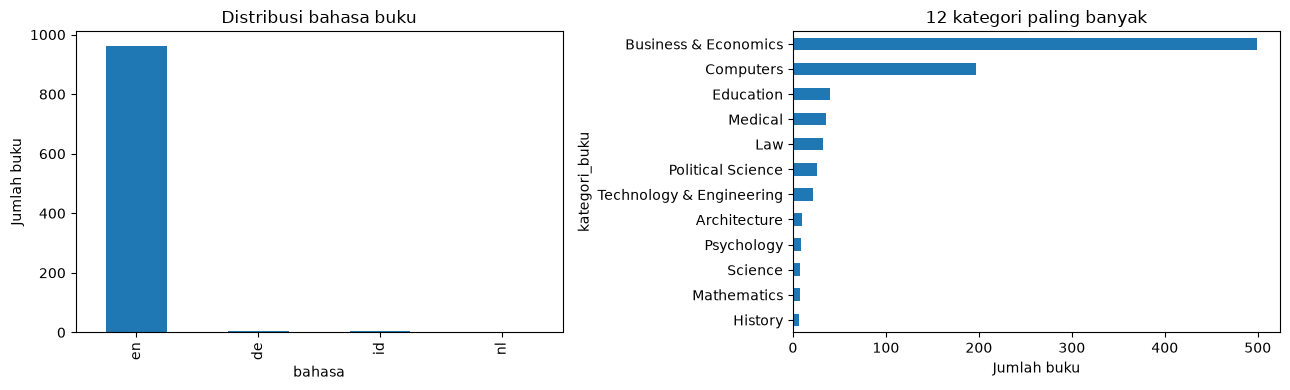

,bahasa,jumlah
0,en,963
1,de,5
2,id,3
3,nl,2


In [4]:
bahasa = books.bahasa.replace('', 'Tidak diketahui').value_counts()
kategori = books.kategori_buku.replace('', 'Tidak diketahui').value_counts().head(12)
fig, axes = plt.subplots(1, 2, figsize=(13,4))
bahasa.head(8).plot(kind='bar', ax=axes[0], title='Distribusi bahasa buku')
kategori.sort_values().plot(kind='barh', ax=axes[1], title='12 kategori paling banyak')
axes[0].set_ylabel('Jumlah buku')
axes[1].set_xlabel('Jumlah buku')
plt.tight_layout()
plt.savefig(FIG/'02_bahasa_kategori.png',dpi=160)
plt.show()
display(bahasa.rename_axis('bahasa').reset_index(name='jumlah'))

## 5. Tahun terbit dan panjang abstrak
Metadata tahun dan panjang abstrak saya periksa, karena abstrak sangat pendek dapat mengurangi bukti relevansi.

Tahun valid: 973 Rentang: 1895 - 2026
Abstrak kosong: 0
Abstrak < 30 kata: 65


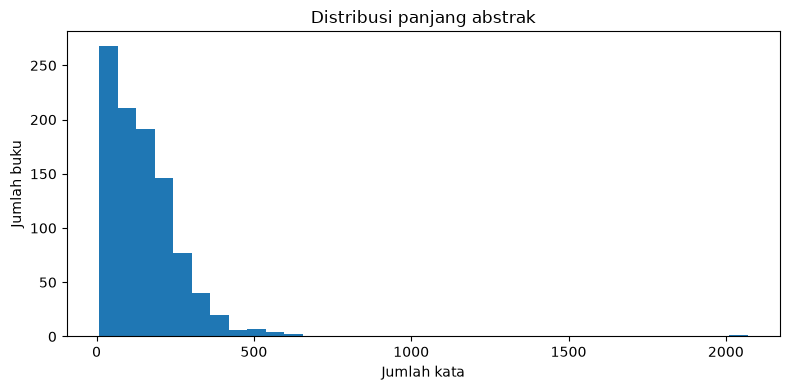

In [5]:
tahun = pd.to_numeric(books.tahun, errors='coerce')
panjang = books['abstrak'].fillna('').str.split().apply(len)
print('Tahun valid:', int(tahun.notna().sum()), 'Rentang:', tahun.min(), '-', tahun.max())
print('Abstrak kosong:', int((panjang==0).sum()))
print('Abstrak < 30 kata:', int((panjang<30).sum()))
fig,ax=plt.subplots(figsize=(8,4))
ax.hist(panjang,bins=35)
ax.set(title='Distribusi panjang abstrak',xlabel='Jumlah kata',ylabel='Jumlah buku')
plt.tight_layout();plt.savefig(FIG/'02_panjang_abstrak.png',dpi=160);plt.show()

## 6. Simpan ringkasan
Ringkasan ini dipakai untuk menjelaskan kondisi awal dataset kepada mentor.

In [6]:
ringkasan = pd.DataFrame([{'jumlah_buku':len(books),'jumlah_kompetensi':len(comps),
    'judul_unik':books.judul.nunique(),'abstrak_kosong':int((panjang==0).sum()),
    'tahun_valid':int(tahun.notna().sum()),'jumlah_bahasa':books.bahasa.nunique()}])
ringkasan.to_csv(OUT/'ringkasan_dataset.csv',index=False)
display(ringkasan)
assert ringkasan.jumlah_buku.iloc[0] == len(books)

,jumlah_buku,jumlah_kompetensi,judul_unik,abstrak_kosong,tahun_valid,jumlah_bahasa
0,973,67,937,0,973,4


## Kesimpulan tahap
Profil data, sebaran bahasa dan panjang abstrak sudah tersedia. Tahap berikutnya memeriksa duplikasi dan kelengkapan metadata secara lebih mendalam sebelum data dibersihkan.